### Midterm Checkpoint

# ICS 691G Mid-Term Checkpoint
**Project:** Can Neighbor-Joining Clustering Reveal if Geography or Host Drives H5N Evolution?
**Name:** Michael Lee

In [1]:
!pip install biopython

In [2]:
import time
import tracemalloc
import numpy as np
from scipy import sparse
from Bio import SeqIO

import io
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from Bio import Phylo

In [3]:
# Number of entries in our dataset
ENTRIES = 100

In [4]:
from Bio import Entrez

# NCBI requires you to provide your email address for API usage
Entrez.email = "mlee31@hawaii.edu" 

search_handle = Entrez.esearch(
    db="nucleotide",
    term="Alphainfluenzavirus[Organism] AND H5N*[All Fields]",
    retmax=ENTRIES
)
search_results = Entrez.read(search_handle)
search_handle.close()

id_list = search_results["IdList"]
print(f"Found {len(id_list)} sequence IDs.")

# Fetch in GenBank format (contains both nucleotides AND host/geography metadata)
fetch_handle = Entrez.efetch(
    db="nucleotide",
    id=id_list,
    rettype="gb",
    retmode="text"
)
gb_data = fetch_handle.read()
fetch_handle.close()

with open(f"data/h5n_toy_data_{ENTRIES}.gb", "w") as f:
    f.write(gb_data)

print("Data downloaded successfully!")

Found 100 sequence IDs.
Data downloaded successfully!


In [5]:
TOY_DATA_FILE = f"data/h5n_toy_data_{ENTRIES}.gb"

sequences = []
headers = []
geography_labels = []
host_labels = []

for record in SeqIO.parse(TOY_DATA_FILE, "genbank"):
    sequences.append(str(record.seq))
    headers.append(record.description)
    
    # Extract metadata from the 'source' feature
    host = "Unknown_Host"
    geo = "Unknown_Region"
    for feature in record.features:
        if feature.type == "source":
            host = feature.qualifiers.get("host", ["Unknown_Host"])[0]
            # NCBI recently transitioned from 'country' to 'geo_loc_name'
            geo = feature.qualifiers.get(
                "geo_loc_name",
                feature.qualifiers.get("country", ["Unknown_Region"])
            )[0]
            # Optional: keep just the country/region before the colon (e.g., "USA: California" -> "USA")
            geo = geo.split(":")[0].strip()
            break
            
    host_labels.append(host)
    geography_labels.append(geo)

print(f"Loaded {len(sequences)} sequences for preliminary benchmarking.")

Loaded 100 sequences for preliminary benchmarking.


In [6]:
def load_genbank(path, product_keyword=None, max_records=100, length_tolerance=0.10):
    """
    Loads the data from the data that was downloaded

    path: path to the data
    product_keyword: words found in the description
    max_records: maximum number of records loaded
    length_tolerance: keeps the sequences within the length_tolerance of the median
    
    """ 
    records = [
        rec
        for rec in SeqIO.parse(path, "genbank")
        if product_keyword is None or product_keyword.lower() in rec.description.lower()
    ]
    if not records:
        raise ValueError(f"No records mention '{product_keyword}'.")

    # Take only the first `max_records` matching sequences
    if max_records is not None:
        records = records[:max_records]

    median = np.median([len(r.seq) for r in records])
    lo, hi = median * (1 - length_tolerance), median * (1 + length_tolerance)
    records = [r for r in records if lo <= len(r.seq) <= hi]

    ids, seqs, host_by_id, geo_by_id = [], [], {}, {}
    for rec in records:
        host, geo = "Unknown_Host", "Unknown_Region"
        for feat in rec.features:
            if feat.type == "source":
                host = feat.qualifiers.get("host", [host])[0]
                geo = feat.qualifiers.get(
                    "geo_loc_name", feat.qualifiers.get("country", [geo])
                )[0]
                geo = geo.split(":")[0].strip()
                break
        ids.append(rec.id)
        seqs.append(str(rec.seq).upper())
        host_by_id[rec.id] = host
        geo_by_id[rec.id] = geo

    print(f"Kept {len(ids)} sequences (median length {median:.0f}).")
    return ids, seqs, host_by_id, geo_by_id

In [7]:
def kmer_distance_matrix(seqs, k=11):
    """
    Distance matrix straight from the raw (unaligned) sequences.

    Each sequence becomes the set of its distinct k-mers. For a pair, the Jaccard
    index J = |A & B| / |A | B| is converted to an estimated substitutions-per-site
    distance:   D = -ln(2J / (1 + J)) / k      (the Mash distance, Ondov et al. 2016)

    - k-mers containing anything other than A/C/G/T are skipped.
    - Indels barely matter, because no column-by-column comparison is made.
    - Keep sequences similar in length (load_genbank does this): a much shorter
    sequence has fewer k-mers and looks artificially distant.
    - Distances come out roughly 10% below Jukes-Cantor on simulated data, with a
    correlation of about 0.997, so branch lengths are on a slightly different
    scale than an alignment-based tree.
    """
    if not 1 <= k <= 31:
        raise ValueError("k must be between 1 and 31.")

    lookup = np.full(256, -1, dtype=np.int64)  # ASCII code -> 0..3, or -1 if not ACGT
    for code, base in enumerate("ACGT"):
        lookup[ord(base)] = code
    powers = 4 ** np.arange(k - 1, -1, -1, dtype=np.int64)  # turns k bases into one integer

    rows, codes = [], []
    for r, s in enumerate(seqs):
        a = lookup[np.frombuffer(s.upper().encode(), dtype=np.uint8)]
        if len(a) < k:
            raise ValueError(f"Sequence {r} is shorter than k={k}.")
        windows = np.lib.stride_tricks.sliding_window_view(a, k)  # every k-mer
        kmers = np.unique(windows[(windows >= 0).all(axis=1)] @ powers)
        if len(kmers) == 0:
            raise ValueError(f"Sequence {r} has no k-mers made only of A/C/G/T.")
        rows.append(np.full(len(kmers), r))
        codes.append(kmers)

    rows, codes = np.concatenate(rows), np.concatenate(codes)
    _, cols = np.unique(codes, return_inverse=True)  # compact column ids
    n = len(seqs)
    X = sparse.csr_matrix(  # X[i, c] = 1 if sequence i contains k-mer c
        (np.ones(len(rows), dtype=np.float32), (rows, cols)),
        shape=(n, cols.max() + 1),
    )
    shared = (X @ X.T).toarray()  # shared[i, j] = number of k-mers both have
    sizes = np.asarray(X.sum(axis=1)).ravel()
    J = shared / (sizes[:, None] + sizes[None, :] - shared)

    if (J[~np.eye(n, dtype=bool)] == 0).any():
        raise ValueError("Some pairs share no k-mers; try a smaller k.")
    D = -np.log(2 * J / (1 + J)) / k
    np.fill_diagonal(D, 0.0)
    return D

In [8]:
class Node:
    """Node for a phylogenentic tree"""
    def __init__(self, name, children=None):
        self.name = name
        self.children = children or []

    def is_leaf(self):
        # If we have no child node, then we are a leaf
        return not self.children

    def newick(self, digits=5):
        """Recursively display the tree"""
        def rec(node):
            if node.is_leaf():
                return node.name
            parts = [f"{rec(c)}:{length:.{digits}f}" for c, length in node.children]
            return "(" + ",".join(parts) + ")"
        return rec(self) + ";"

In [9]:
def _validate(labels, matrix):
    """Validate to make sure invariants are true"""
    D = np.array(matrix, float)
    n = len(labels)

    if n < 2: # Needs to at least be a 2 x 2, 1 is trivial
        raise ValueError("Needs at least 2 taxa")
    if len(set(labels)) != n: # Labels are not unique
        raise ValueError("Labels are not unique")
    if D.shape != (n, n): # Not square
        raise ValueError("Distance matrix must be square and match the labels")
    if not np.allclose(D, D.T): # Not symmetric
        raise ValueError("Distance matrix is not symmetric")
    if not np.allclose(np.diag(D), 0): # Diagonal is not all zeros
        raise ValueError("Diagonal is not all zeros")

In [10]:
def neighbor_joining(labels, matrix):
    """
    Build an unrooted neighbor-joining tree

    labels: list of unique taxons names,
    matrix: n x n symmetrical matrix with 0's on the diagonal

    Returns the root Node of the tree; 
    if it is unrooted, then it returns the internal node where the last three (or two) branches (or edge) meet 
    """
    # Ensure that the inputs are correct
    _validate(labels, matrix)

    # Create distance matrix
    D = np.array(matrix, dtype=float)

    # Row k of D corresponds to nodes[k]
    nodes = [Node(name) for name in labels]
    # Number of nodes created
    counter = 0

    # Do neighbor joining recursively 
    while len(nodes) > 2:
        n = len(nodes)

        # Net divergence for each taxon
        r = D.sum(axis=1)

        # Compute Q, which is used to define how good of a candidate they are to join?
        Q = (n - 2) * D - r[:, None] - r[None, :]

        # Set the lower triangle of the matrix to -inf, so we can ignore index ij vs ji problems
        Q[np.tril_indices(n)] = np.inf

        # Find the smallest value within Q
        i, j = np.unravel_index(np.argmin(Q), Q.shape)
        dij = D[i,j]

        # Calculate the branch lengths to the new node
        # Branch length from taxon i to the new node ij 
        li = 0.5 * dij + (r[i] - r[j]) / (2 * (n-2))
        # Given li we can compute the branch length between taxon j and the new node ij
        lj = dij - li

        # Calculate the distance from the new node to all others
        keep = [k for k in range(n) if k not in (i,j)] # Row and column to keep
        new_row = 0.5 * (D[i, keep] + D[j, keep] - dij) # Distance from new node to nodes we keep

        # Reconstruct the smaller matrix
        m = len(keep)
        D_next = np.zeros((m + 1, m + 1))
        D_next[:m, :m] = D[np.ix_(keep, keep)] # Keep the old values
        D_next[m, :m] = new_row # Add the new row at the end
        D_next[:m, m] = new_row # Add the new row as a column at the end
        D = D_next

        u = Node(f"u{counter}", [(nodes[i], li), (nodes[j], lj)]) # New node
        counter += 1
        nodes = [nodes[k] for k in keep] + [u] # Update nodes to contain the new one

    half = D[0, 1] / 2 # Calculate the midpoint of the last two nodes to place root
    return Node("root", [(nodes[0], half), (nodes[1], half)]) # Root of the tree

In [11]:
# Preprocessing
ids, seqs, host_by_id, geo_by_id = load_genbank(TOY_DATA_FILE, 
                                                max_records=ENTRIES, 
                                                length_tolerance=0.5)

Kept 100 sequences (median length 1540).


In [12]:
# Initialize benchmarking
print("Starting memory and time tracking...")
tracemalloc.start()
start_time = time.time()

Starting memory and time tracking...


In [13]:
# Execute Neighbor Joining
D = kmer_distance_matrix(seqs, k = 5)
tree = neighbor_joining(ids, D)

In [14]:
# Stop tracking
current_memory, peak_memory = tracemalloc.get_traced_memory()
tracemalloc.stop()
end_time = time.time()

runtime = end_time - start_time
memory_mb = peak_memory / (1024 * 1024)

print("=== Preliminary Benchmarking Results ===")
print(f"Data Input Amount: {len(sequences)} nucleotide sequences")
print(f"Peak Memory Usage: {memory_mb:.4f} MB")
print(f"Total Runtime: {runtime:.4f} seconds")
print("========================================")

=== Preliminary Benchmarking Results ===
Data Input Amount: 100 nucleotide sequences
Peak Memory Usage: 3.7987 MB
Total Runtime: 0.0439 seconds


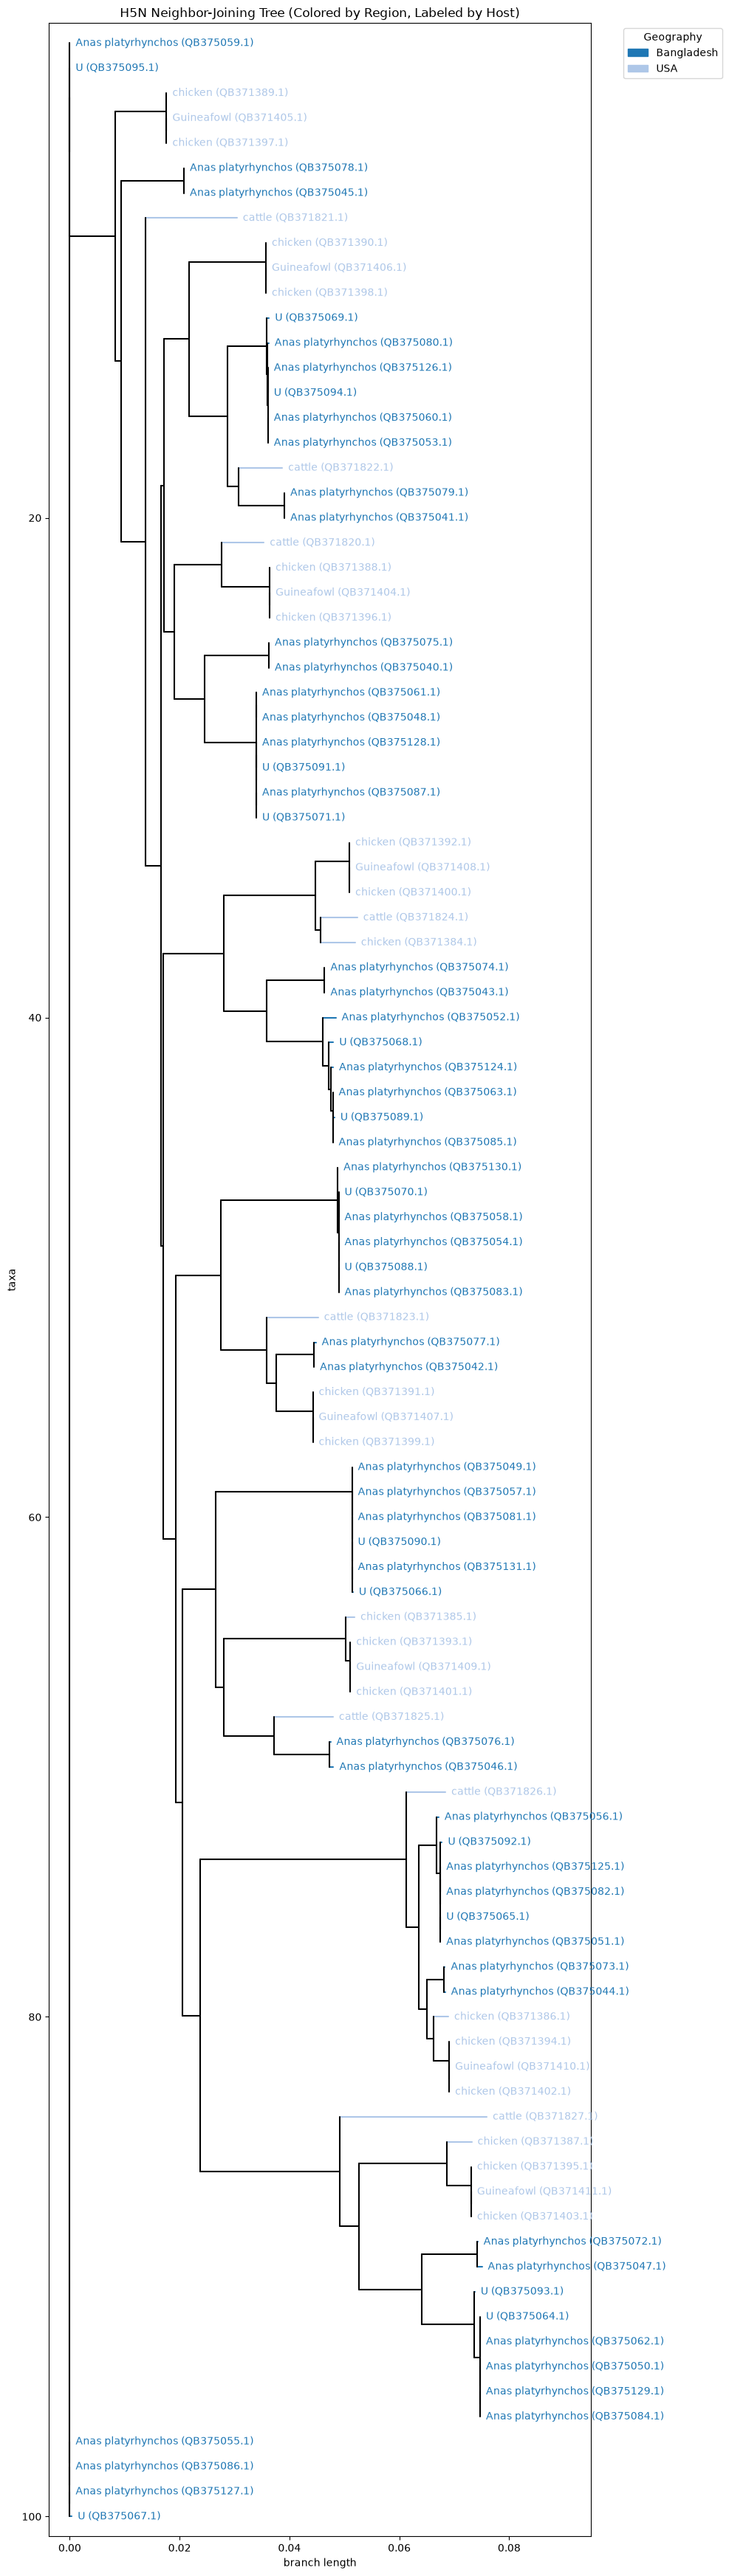

In [15]:
# 1. Convert your custom Node tree to a Bio.Phylo tree
phylo_tree = Phylo.read(io.StringIO(tree.newick()), "newick")

# 2. Assign a distinct hex color to each geographic region
regions = sorted(set(geo_by_id.values()))
cmap = plt.get_cmap("tab20")
region_colors = {region: mcolors.to_hex(cmap(i % 20)) for i, region in enumerate(regions)}

# 3. Pre-populate label_colors AND color the terminal branches
label_colors = {}
for clade in phylo_tree.get_terminals():
    acc = clade.name
    color = region_colors[geo_by_id[acc]]
    clade.color = color  # Colors the branch
    label = f" {host_by_id[acc]} ({acc})"
    label_colors[label] = color  # Colors the text label

def format_label(clade):
    if clade.is_terminal():
        acc = clade.name
        return f" {host_by_id[acc]} ({acc})"
    return ""

# 4. Plot the tree
fig, ax = plt.subplots(figsize=(10, max(5, len(ids) * 0.35)))
Phylo.draw(
    phylo_tree,
    axes=ax,
    do_show=False,
    label_func=format_label,
    label_colors=label_colors,
)

# 5. Add the legend
handles = [mpatches.Patch(color=region_colors[r], label=r) for r in regions]
ax.legend(handles=handles, title="Geography", bbox_to_anchor=(1.05, 1), loc="upper left")
ax.set_title("H5N Neighbor-Joining Tree (Colored by Region, Labeled by Host)")
plt.tight_layout()
plt.show()